# Лабораторна робота 11: Gemini Notebook, Google Colab і GitHub
**Виконав:** Андрусяк Максим  
**Група:** ПІ 25-01
**Варіант:** 2 (Журнал комітів проєкту)

In [2]:
import sys, platform

student = "Андрусяк Максим"
group = "ПІ 25-01"
variant = 2

print("Лабораторна робота: Gemini, Colab, GitHub")
print("Виконав:", student, "| група:", group, "| варіант:", variant)
print("Версія Python:", sys.version.split()[0])
print("Платформа:", platform.system())

Лабораторна робота: Gemini, Colab, GitHub
Виконав: Андрусяк Максим | група: ПІ 25-01 | варіант: 2
Версія Python: 3.13.18
Платформа: Linux


In [3]:
import pandas as pd
import numpy as np

# Створення синтетичного набору даних: Варіант 2 (Журнал комітів проєкту)
data = {
    "commit_id": [f"c{100+i}" for i in range(14)] + ["c102"],  # є дублікат c102
    "author": [
        "Andrusyak M.", "Kovalenko O.", "Melnyk I.", "Andrusyak M.",
        "Shevchenko T.", "Kovalenko O.", None, "Melnyk I.",
        "Andrusyak M.", "Shevchenko T.", "Kovalenko O.", "Melnyk I.",
        "Andrusyak M.", "Shevchenko T.", "Melnyk I."
    ],
    "date": [
        "2026-10-01", "2026-10-02", "2026-10-03", "2026-10-03",
        "2026-10-04", "2026-10-05", "2026-10-06", "2026-10-07",
        "2026-10-08", "2026-10-09", "2026-10-10", "2026-10-11",
        "2026-10-12", "2026-10-13", "2026-10-03"
    ],
    "branch": [
        "main", "dev", "feature/login", "dev", "bugfix/api",
        "main", "dev", "feature/ui", "main", "bugfix/db",
        "dev", "feature/login", "main", "dev", "feature/login"
    ],
    "files_changed": [3, 5, 2, 1, 4, 6, 2, np.nan, 3, 5, 1, 4, 2, 3, 2],
    "lines_added": [45, 120, 34, 12, 89, 210, 18, 65, 50, np.nan, 15, 95, 30, 42, 34],
    "lines_removed": [10, 30, 5, 2, 40, 85, 4, 12, 15, 25, 3, 20, 8, 11, 5]
}

df = pd.DataFrame(data)
print("Початкова таблиця (перші 10 рядків):")
display(df.head(10))
print(f"\nРозмір таблиці: {df.shape[0]} рядків, {df.shape[1]} стовпців")

Початкова таблиця (перші 10 рядків):


,commit_id,author,date,branch,files_changed,lines_added,lines_removed
0,c100,Andrusyak M.,2026-10-01,main,3.0,45.0,10
1,c101,Kovalenko O.,2026-10-02,dev,5.0,120.0,30
2,c102,Melnyk I.,2026-10-03,feature/login,2.0,34.0,5
3,c103,Andrusyak M.,2026-10-03,dev,1.0,12.0,2
4,c104,Shevchenko T.,2026-10-04,bugfix/api,4.0,89.0,40
5,c105,Kovalenko O.,2026-10-05,main,6.0,210.0,85
6,c106,None,2026-10-06,dev,2.0,18.0,4
7,c107,Melnyk I.,2026-10-07,feature/ui,NaN,65.0,12
8,c108,Andrusyak M.,2026-10-08,main,3.0,50.0,15
9,c109,Shevchenko T.,2026-10-09,bugfix/db,5.0,NaN,25



Розмір таблиці: 15 рядків, 7 стовпців


In [4]:
# 1. Перевірка пропусків та дублікатів до очищення
print("Кількість пропусків у стовпцях:")
print(df.isna().sum())
print("\nКількість дублікатів за commit_id:", df.duplicated(subset=["commit_id"]).sum())

# 2. Видалення дублікатів
df_clean = df.drop_duplicates(subset=["commit_id"]).copy()

# 3. Заповнення пропусків
df_clean["author"] = df_clean["author"].fillna("Unknown")
df_clean["files_changed"] = df_clean["files_changed"].fillna(df_clean["files_changed"].median())
df_clean["lines_added"] = df_clean["lines_added"].fillna(df_clean["lines_added"].median())

# 4. Приведення дат та цілих чисел до правильних типів
df_clean["date"] = pd.to_datetime(df_clean["date"])
df_clean["files_changed"] = df_clean["files_changed"].astype(int)
df_clean["lines_added"] = df_clean["lines_added"].astype(int)

print("\nОчищена таблиця (14 унікальних комітів):")
display(df_clean)

Кількість пропусків у стовпцях:
commit_id        0
author           1
date             0
branch           0
files_changed    1
lines_added      1
lines_removed    0
dtype: int64

Кількість дублікатів за commit_id: 1

Очищена таблиця (14 унікальних комітів):


,commit_id,author,date,branch,files_changed,lines_added,lines_removed
0,c100,Andrusyak M.,2026-10-01,main,3,45,10
1,c101,Kovalenko O.,2026-10-02,dev,5,120,30
2,c102,Melnyk I.,2026-10-03,feature/login,2,34,5
3,c103,Andrusyak M.,2026-10-03,dev,1,12,2
4,c104,Shevchenko T.,2026-10-04,bugfix/api,4,89,40
5,c105,Kovalenko O.,2026-10-05,main,6,210,85
6,c106,Unknown,2026-10-06,dev,2,18,4
7,c107,Melnyk I.,2026-10-07,feature/ui,3,65,12
8,c108,Andrusyak M.,2026-10-08,main,3,50,15
9,c109,Shevchenko T.,2026-10-09,bugfix/db,5,45,25


In [5]:
# Додаємо корисну метрику: чиста зміна рядків коду (net_lines)
df_clean["net_lines"] = df_clean["lines_added"] - df_clean["lines_removed"]

print("=== 1. Загальна статистика числових показників ===")
display(df_clean[["files_changed", "lines_added", "lines_removed", "net_lines"]].describe().round(2))

print("\n=== 2. Активність за авторами ===")
author_stats = df_clean.groupby("author").agg(
    commits_count=("commit_id", "count"),
    total_files=("files_changed", "sum"),
    total_added=("lines_added", "sum"),
    total_removed=("lines_removed", "sum"),
    net_lines=("net_lines", "sum")
).sort_values(by="commits_count", ascending=False)
display(author_stats)

print("\n=== 3. Розподіл комітів за гілками ===")
branch_stats = df_clean.groupby("branch").agg(
    commits=("commit_id", "count"),
    avg_files=("files_changed", "mean"),
    total_added=("lines_added", "sum")
).round(2)
display(branch_stats)

=== 1. Загальна статистика числових показників ===


,files_changed,lines_added,lines_removed,net_lines
count,14.00,14.00,14.00,14.00
mean,3.14,62.14,19.29,42.86
std,1.51,53.11,21.93,33.31
min,1.00,12.00,2.00,10.00
25%,2.00,31.00,5.75,20.50
50%,3.00,45.00,11.50,33.00
75%,4.00,83.00,23.75,52.00
max,6.00,210.00,85.00,125.00



=== 2. Активність за авторами ===


,commits_count,total_files,total_added,total_removed,net_lines
author,,,,,
Andrusyak M.,4,9,137,35,102
Kovalenko O.,3,12,345,118,227
Melnyk I.,3,9,194,37,157
Shevchenko T.,3,12,176,76,100
Unknown,1,2,18,4,14



=== 3. Розподіл комітів за гілками ===


,commits,avg_files,total_added
branch,,,
bugfix/api,1,4.0,89
bugfix/db,1,5.0,45
dev,5,2.4,207
feature/login,2,3.0,129
feature/ui,1,3.0,65
main,4,3.5,335


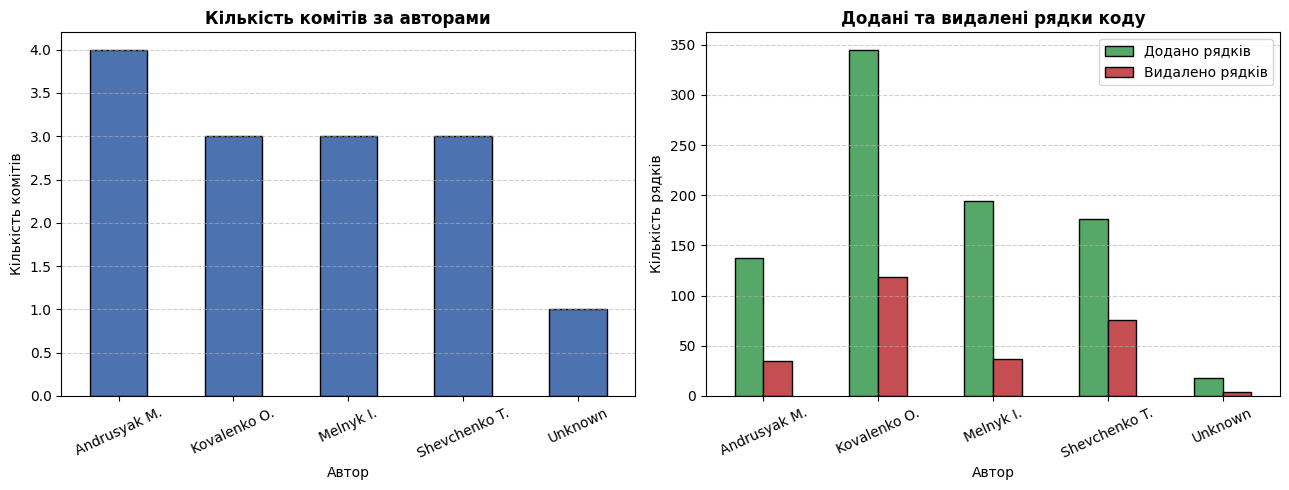

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Графік 1: Кількість комітів за авторами
author_stats["commits_count"].plot(
    kind="bar", ax=axes[0], color="#4C72B0", edgecolor="black"
)
axes[0].set_title("Кількість комітів за авторами", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Автор")
axes[0].set_ylabel("Кількість комітів")
axes[0].tick_params(axis="x", rotation=25)
axes[0].grid(axis="y", linestyle="--", alpha=0.6)

# Графік 2: Додані та видалені рядки коду за авторами
author_stats[["total_added", "total_removed"]].plot(
    kind="bar", ax=axes[1], color=["#55A868", "#C44E52"], edgecolor="black"
)
axes[1].set_title("Додані та видалені рядки коду", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Автор")
axes[1].set_ylabel("Кількість рядків")
axes[1].legend(["Додано рядків", "Видалено рядків"])
axes[1].tick_params(axis="x", rotation=25)
axes[1].grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig("commits_charts.png", dpi=150)
plt.show()

In [7]:
# Промпт для AI: На основі таблиці df_clean знайди коміт з найбільшою кількістю змінених файлів і виведи інформацію про нього

max_files_commit = df_clean.loc[df_clean["files_changed"].idxmax()]

print("Коміт із найбільшою кількістю змінених файлів:")
print(f"ID коміту: {max_files_commit['commit_id']}")
print(f"Автор: {max_files_commit['author']}")
print(f"Дата: {max_files_commit['date'].strftime('%Y-%m-%d')}")
print(f"Гілка: {max_files_commit['branch']}")
print(f"Змінено файлів: {max_files_commit['files_changed']}")
print(f"Додано / видалено рядків: +{max_files_commit['lines_added']} / -{max_files_commit['lines_removed']}")

Коміт із найбільшою кількістю змінених файлів:
ID коміту: c105
Автор: Kovalenko O.
Дата: 2026-10-05
Гілка: main
Змінено файлів: 6
Додано / видалено рядків: +210 / -85


In [8]:
# Збереження очищеного журналу комітів та статистики у CSV-файли
df_clean.to_csv("commits_clean.csv", index=False)
author_stats.to_csv("author_summary.csv")

print("Файли успішно збережено у середовищі Colab:")
print("- commits_clean.csv")
print("- author_summary.csv")
print("- commits_charts.png (збережено раніше)")

Файли успішно збережено у середовищі Colab:
- commits_clean.csv
- author_summary.csv
- commits_charts.png (збережено раніше)
